In [ ]:
pip install together

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.4/86.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.3/120.3 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 2.1 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.20.0
    Uninstalling typer-0.20.0:
      Successfully uninstalled typer-0.20.0


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import pickle
import re
import time
import json
import pandas as pd
from tqdm import tqdm
from together import Together

╭───────────────────────────────────────────── 🚀 New SDK Available ──────────────────────────────────────────────╮
│ Together Python SDK 2.0 is now available!                                                                       │
│                                                                                                                 │
│ Install the beta:                                                                                               │
│ pip install --pre together  or  uv add together --prerelease allow                                              │
│                                                                                                                 │
│ New SDK: ]8;id=502983;https://github.com/togethercomputer/together-py\https://github.com/togethercomputer/together-py]8;;\                                                        │
│ Migration guide: ]8;id=514848;https://docs.together.ai/docs/pythonv2-migration-guide\https://docs.together.ai/docs/pythonv2-migration-guide]8;;\                                         │
│                                                                                                                 │
│ This package will be maintained until January 2026.                                                             │
│ Set TOGETHER_NO_BANNER=1 to hide this message.                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [ ]:
MODEL_NAME = "moonshotai/Kimi-K2-Instruct-0905"
#MODEL_NAME = "Qwen/Qwen3-Next-80B-A3B-Instruct"
API_KEY = 'xxx'

client = Together(api_key=API_KEY)

THINK_PATTERN = re.compile(r"^(.*?)</think>", re.DOTALL | re.IGNORECASE)


ANALYSIS_PROMPT = '''
# Role
You are an expert logical analyst. Your task is to classify reasoning strategies in AI thinking traces for logical deduction tasks,
where the AI needs to use a certain strategy infer ground truth variables (e.g., A, B) from a logic function (e.g., XOR) using experimental trials (e.g., V0=1, V1=1... result=1).

## 1. Permutation (Systematic/Heuristic Search)
- **Core Logic:** The model identifies the solution by testing specific hypotheses (variable pairs) against data points, one by one or in small batches.
- **Key Indicators:**
    - Examples："Let's test V0 and V1... Next, let's try V2 and V3..."
    - If the model uses trials to narrow down candidates，and then proceeds to verify remaining pairs individually, it is Elimination.
    - If the agent tests a pair, fails, and immediately moves to the "next available pair" in a sequence, it is Permutation.
- **Label:** "permutation"

## 2. Elimination (Deductive Pruning)
- **Core Logic:** The model uses "Logical Pruning." It derives a general rule from the trial data that pre-emptively removes candidate(s) from consideration.
- **Key Indicators:**
    - Examples：
      "Trial X is 0, and V1 and V2 are 1, therefore NONE of these can be part of the solution. I can now ignore all pairs involving V1 and V2." (remove multiple candidates)
      "Trial X is 1, so the combination V0 and V1 can not be true." (remove one candidate)
    - If the pair was extracted from data features (e.g., "Trial 2 is the only positive outcome, and only V1 and V4 are 1 there, so it MUST be them"), it is Elimination.
    - Elimination happen **before** or **during** the search to narrow the search space. Simply checking if a found answer is correct is NOT elimination.
- **Label:** "elimination"

## 3. None
- Provide the direct answer (with or without explaination) without any explicit strategy shown.
- **Label:** "none"

# Example 1
- **Case A:** Model says "V1 is in a 0-result trial, so V1 is out. Now I'll test the remaining (V0, V2), (V0, V3)..." -> **Label: elimination** (Reason: Pruning occurred).
- **Case B:** Model says "Trial 1 is 1, maybe it's V1 and V2? Let's check V1+V2. Yes! It works." -> **Label: permutation** (Reason: Hypothesize-and-test, no pruning).

# Example 2
- **Case A:** Model says "Is it V0 and V1? Trial 1 says result is 0, so no. Let's try V0 and V2." -> **Label: permutation** (Reason: It picks a pair first, then checks it.)
- **Case B:** Model says "Trial 1 has V0, V1 and result is 0. This means neither V0 nor V1 can be the active variable. Therefore, the only remaining candidate is V2." -> **Label: elimination** (Reason: It uses the trial to kill candidates first, even if it only kills one or two.)

# Output Requirements
- Focus on the **process**, not the correctness of the answer.
- Provide a brief reasoning_analysis explaining the "why".
- Return ONLY a JSON object:
{
  "reasoning_analysis": "A concise explanation of why this fits the chosen label.",
  "strategy_type": "permutation" | "elimination" | "none"
}

# Input Trace
<thinking_trace>
{{THINKING_TRACE}}
</thinking_trace>
'''

In [ ]:
def process_single_file(input_path):

    try:
        with open(input_path, 'rb') as f:
            data = pickle.load(f)
    except Exception as e:
        print(f"Error loading {input_path}: {e}")
        return None

    processed_data = []

    items = data if isinstance(data, list) else [data]
    file_name = os.path.basename(input_path)

    for item in tqdm(items, desc=f"Processing {file_name}", leave=False):
        # Extract Thinking Trace
        raw_response = item.get('llm_raw_response', '')
        match_think = re.search(THINK_PATTERN, raw_response)
        trace_content = match_think.group(1).strip() if match_think else raw_response.strip()

        # Skip inference if trace is empty
        if not trace_content:
            item['strategy_type'] = 'none'
            item['strategy_analysis'] = 'No thinking trace found'
            processed_data.append(item)
            continue

        prompt = ANALYSIS_PROMPT.replace("{{THINKING_TRACE}}", trace_content)

        for attempt in range(3):
            try:
                res = client.chat.completions.create(
                    model=MODEL_NAME,
                    messages=[{"role": "user", "content": prompt}],
                    temperature=0.1
                )
                raw_out = res.choices[0].message.content
                match_json = re.search(r'\{.*\}', raw_out, re.DOTALL)

                if match_json:
                    analysis_json = json.loads(match_json.group(0))
                    break
                else:
                    analysis_json = {"strategy_type": "none", "reasoning_analysis": "JSON parsing failed (No brackets found)"}

            except Exception as e:
                if attempt < 2:
                    print(f"Attempt {attempt + 1} failed, retrying... Error: {e}") # Optional log
                    time.sleep(2)
                else:
                    print(f"All {3} attempts failed. Error: {e}")
                    analysis_json = {"strategy_type": "error", "reasoning_analysis": f"Final Error: {str(e)}"}

        item['strategy_type'] = analysis_json.get('strategy_type', 'none')
        item['strategy_analysis'] = analysis_json.get('reasoning_analysis', '')

        processed_data.append(item)

    return processed_data

In [ ]:

input_dir = "/content/drive/MyDrive/inference-time-scale-adaptation/model_trajectory/deepseek-r1"  # Modify as needed
output_dir = "/content/drive/MyDrive/inference-time-scale-adaptation/analyzed_trajectory/analyzed_deepseek-r1" # Modify as needed

if not os.path.exists(output_dir):
    os.makedirs(output_dir)

pkl_files = [f for f in os.listdir(input_dir) if f.endswith('.pkl')]
print(f"Starting Batch Processing. Total files: {len(pkl_files)}")

for i, filename in enumerate(pkl_files):
    in_path = os.path.join(input_dir, filename)
    out_path = os.path.join(output_dir, f'analyzed_{filename}')

    if os.path.exists(out_path):
         continue

    print(f"[{i+1}/{len(pkl_files)}] Starting {filename}...")
    processed_list = process_single_file(in_path)

    if processed_list is not None:
        try:
            with open(out_path, 'wb') as f:
                pickle.dump(processed_list, f)
            print(f"  Saved {filename}")
        except Exception as e:
            print(f"  Error saving {filename}: {e}")
    else:
        print(f" Skipped {filename} due to load error")

print("\nDONE.")

Starting Batch Processing. Total files: 10
[2/10] Starting 2_vars_adaptive_sample_5_(NOT_A)_AND_(NOT_B)_DeepSeek-R1.pkl...


  Saved 2_vars_adaptive_sample_5_(NOT_A)_AND_(NOT_B)_DeepSeek-R1.pkl
[3/10] Starting 2_vars_adaptive_sample_5_A_XNOR_B_DeepSeek-R1.pkl...


  Saved 2_vars_adaptive_sample_5_A_XNOR_B_DeepSeek-R1.pkl
[4/10] Starting 2_vars_adaptive_sample_5_A_AND_B_DeepSeek-R1.pkl...


  Saved 2_vars_adaptive_sample_5_A_AND_B_DeepSeek-R1.pkl
[5/10] Starting 2_vars_adaptive_sample_5_A_OR_B_DeepSeek-R1.pkl...


  Saved 2_vars_adaptive_sample_5_A_OR_B_DeepSeek-R1.pkl
[6/10] Starting 2_vars_adaptive_sample_5_A_XOR_B_DeepSeek-R1.pkl...


  Saved 2_vars_adaptive_sample_5_A_XOR_B_DeepSeek-R1.pkl
[7/10] Starting 2_vars_adaptive_sample_5_A_OR_(NOT_B)_DeepSeek-R1.pkl...


  Saved 2_vars_adaptive_sample_5_A_OR_(NOT_B)_DeepSeek-R1.pkl
[8/10] Starting 2_vars_adaptive_sample_5_A_AND_(NOT_B)_DeepSeek-R1.pkl...


  Saved 2_vars_adaptive_sample_5_A_AND_(NOT_B)_DeepSeek-R1.pkl
[9/10] Starting 2_vars_adaptive_sample_5_(NOT_A)_OR_B_DeepSeek-R1.pkl...


  Saved 2_vars_adaptive_sample_5_(NOT_A)_OR_B_DeepSeek-R1.pkl
[10/10] Starting 2_vars_adaptive_sample_5_(NOT_A)_AND_B_DeepSeek-R1.pkl...


  Saved 2_vars_adaptive_sample_5_(NOT_A)_AND_B_DeepSeek-R1.pkl

DONE.


# Inspect data

<Figure size 1000x600 with 0 Axes>

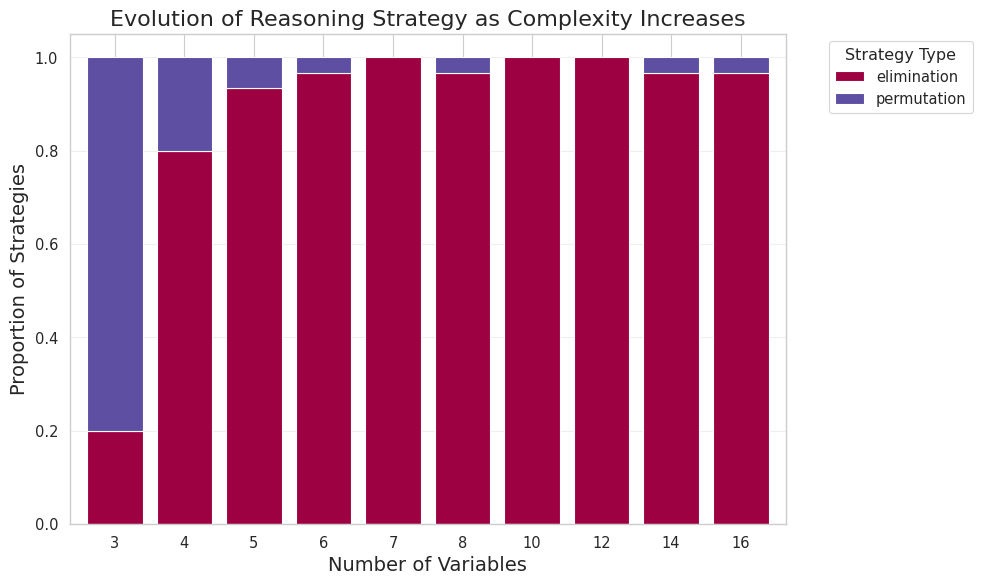

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

INPUT_PKL_PATH = '/content/drive/MyDrive/infer_scale_reason/results/analyzed_deepseek-r1/analyzed_2_vars_adaptive_sample_5_NOT_(A_AND_B)_DeepSeek-R1.pkl' 
with open(INPUT_PKL_PATH, 'rb') as f:
    data = pickle.load(f)

rows = []
for item in data:
    
    row = {
        'num_vars': item.get('num_vars'),
        'num_trials': item.get('num_trials'),
        'is_correct': item.get('is_correct'),
        'char_count': item.get('char_count'),
        'acc_int': 1 if item.get('is_correct') else 0 
    }



    row['strategy_type'] = item.get('strategy_type', 'none')
    rows.append(row)

df = pd.DataFrame(rows)

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

def plot_strategy_distribution(df):
    
    strategy_counts = df.groupby(['num_vars', 'strategy_type']).size().reset_index(name='counts')
    total_counts = df.groupby('num_vars').size().reset_index(name='total')
    strategy_ratio = pd.merge(strategy_counts, total_counts, on='num_vars')
    strategy_ratio['ratio'] = strategy_ratio['counts'] / strategy_ratio['total']

    plt.figure(figsize=(10, 6))

    pivot_df = df.groupby(['num_vars', 'strategy_type']).size().unstack(fill_value=0)
    pivot_df = pivot_df.div(pivot_df.sum(axis=1), axis=0)

    ax = pivot_df.plot(kind='bar', stacked=True, colormap='Spectral', figsize=(10, 6), width=0.8)

    plt.title('Evolution of Reasoning Strategy as Complexity Increases', fontsize=16)
    plt.xlabel('Number of Variables', fontsize=14)
    plt.ylabel('Proportion of Strategies', fontsize=14)
    plt.legend(title='Strategy Type', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xticks(rotation=0)
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_strategy_distribution(df)